# Fake News Detection on IFND
## Student 2: TF-IDF with Linear Support Vector Machine
**Approach:** traditional machine learning. **Expected outcome:** a high-performance text classifier using margin-based learning.

Run with **Runtime > Run all**. No GPU is needed; the grid search takes a few minutes.

In [1]:
import numpy as np
import joblib
import nltk

SEED = 42
np.random.seed(SEED)

## 1. Load IFND and create the shared partitions
This cell downloads IFND from the authors' repository and creates the 70/15/15 train, validation and test partitions shared by all four students. It stops with an error if the file or partitions differ.

Cleaning applied before partitioning: repair broken text encoding, remove headlines shorter than three words, remove headlines that appear with both labels, and keep one copy of each repeated headline.

Only the headline (`Statement`) is used as input. `Web` and `Category` almost reveal the label directly (for example, every `MISLEADING` row is fake), so using them would inflate the results.

In [2]:
# SHARED CELL - keep identical in all four notebooks so the partitions stay identical.
import hashlib, os, re, urllib.request
import pandas as pd

DATA_URL = ('https://raw.githubusercontent.com/sonalgarg174/Dataset/'
            'f47d8407595c288d2a9c4f0f74a5e721a11995b8/IFND.csv')  # authors' repo, pinned commit
DATA_PATH = 'IFND.csv'
FILE_SHA256 = '3728c7b785ea93c9dadcc61a4c549c0eddd71a5fb6a1a31be08b5235ee4f5bfa'
SPLIT_FINGERPRINT = 'd17a2299ad1e64b524d50ac41e3b9828308b4c483a80ced900d85fc913777544'

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
with open(DATA_PATH, 'rb') as f:
    assert hashlib.sha256(f.read()).hexdigest() == FILE_SHA256, 'IFND.csv differs from the agreed file'

raw = pd.read_csv(DATA_PATH, encoding='latin-1', dtype=str, keep_default_na=False)

# The file mixes several broken encodings. Restore apostrophes and drop the remaining debris,
# otherwise a model can learn the scraper's encoding instead of the news content.
APOSTROPHES = ['\x92', '\xd5', '\x89\xdb\xaa', '\xe2\x80\x99', '\xef\xbf\xbd']

def repair_text(text):
    for broken in APOSTROPHES:
        text = text.replace(broken, "'")
    text = re.sub(r'[^\x00-\x7f]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df = pd.DataFrame({
    'id': raw['id'],
    'text': raw['Statement'].map(repair_text),
    'label': raw['Label'].str.strip().str.lower().map({'fake': 1, 'true': 0}),  # Fake = 1, Real = 0
    'source': raw['Web'].str.strip().str.upper(),
})
df['key'] = df['text'].str.lower().str.replace(r'[^a-z0-9]+', ' ', regex=True).str.strip()

rows_loaded = len(df)
df = df[df['key'].str.split().str.len() >= 3]                      # too short to classify
df = df[df.groupby('key')['label'].transform('nunique') == 1]      # same headline, both labels
df = df.drop_duplicates('key').copy()                              # a repeat must not span partitions

# Partition: sort each class by a hash of the headline, then cut 70/15/15. This is a reproducible
# stratified shuffle that does not depend on the installed numpy or scikit-learn version.
df['hash'] = df['key'].map(lambda k: hashlib.sha256(k.encode()).hexdigest())
df = df.sort_values('hash').reset_index(drop=True)
rank = df.groupby('label').cumcount()
size = df.groupby('label')['label'].transform('size')
df['split'] = 'test'
df.loc[rank < (size * 0.85).astype(int), 'split'] = 'val'
df.loc[rank < (size * 0.70).astype(int), 'split'] = 'train'

# Flags used only for the robustness check at the end, never as model inputs.
GIVEAWAY = (r'\b(fact check|factcheck|fake|false|falsely|viral|claim|claims|claimed|misleading|hoax|'
            r'rumou?r|debunk|no this|not a|shared as|shared with|morphed|doctored|old video|old photo|'
            r'video|photo|image|picture)\b')
df['is_augmented'] = df['source'].eq('AUGMENT')
df['has_giveaway'] = df['key'].str.contains(GIVEAWAY.replace('(', '(?:'), regex=True)

fingerprint = hashlib.sha256('\n'.join(df['hash'] + df['split']).encode()).hexdigest()
if SPLIT_FINGERPRINT.startswith('__'):
    print('Fingerprint not pinned yet')
else:
    assert fingerprint == SPLIT_FINGERPRINT, 'Partitions differ from the agreed partitions'

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Rows loaded {rows_loaded:,} | usable after cleaning {len(df):,}')
print('Partition fingerprint:', fingerprint[:16])
print(df.groupby('split')['label'].agg(rows='size', fake='sum', fake_share='mean').round(3))

Rows loaded 56,714 | usable after cleaning 47,892
Partition fingerprint: d17a2299ad1e64b5
        rows   fake  fake_share
split                          
test    7185   2350       0.327
train  33523  10964       0.327
val     7184   2350       0.327


## 2. Shared evaluation
Accuracy, precision, recall and F1 are computed the same way in every notebook. **Fake is the positive class**, so recall means the share of fake headlines that were caught. (The dataset's README describes 1 as true news, while the CSV itself uses `TRUE` and `Fake`; this project sets Fake = 1.)

In [3]:
# SHARED CELL - the same evaluation for all four approaches.
import json
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)

def compute_metrics(y_true, y_pred):
    """Precision, recall and F1 treat Fake (1) as the positive class."""
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0)}

def evaluate_on_test(y_pred, title):
    y_true = test_df['label'].values
    print(classification_report(y_true, y_pred, target_names=['Real', 'Fake'], digits=4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['Real', 'Fake'],
                                            cmap='Blues', values_format=',d')
    plt.title(title)
    plt.show()
    return compute_metrics(y_true, y_pred)

def robustness_check(y_pred):
    """Same predictions, scored on harder parts of the test partition."""
    subsets = {'All test headlines': pd.Series(True, index=test_df.index),
               'Excluding synthetic (AUGMENT)': ~test_df['is_augmented'],
               'Without giveaway words': ~test_df['has_giveaway'],
               'Neither synthetic nor giveaway': ~test_df['is_augmented'] & ~test_df['has_giveaway']}
    rows = []
    for name, mask in subsets.items():
        scores = compute_metrics(test_df.loc[mask, 'label'], y_pred[mask.values])
        rows.append({'subset': name, 'rows': int(mask.sum()),
                     'fake_rows': int(test_df.loc[mask, 'label'].sum()), **scores})
    return pd.DataFrame(rows).set_index('subset').round(4)

def save_results(student, algorithm, y_pred, test_metrics, robustness, details):
    os.makedirs('results', exist_ok=True)
    report = {'student': student, 'algorithm': algorithm, 'partition_fingerprint': fingerprint,
              'test_metrics': test_metrics, 'robustness': robustness.reset_index().to_dict('records'),
              'details': details}
    with open(f'results/student_{student}_metrics.json', 'w') as f:
        json.dump(report, f, indent=2, default=str)
    pd.DataFrame({'id': test_df['id'], 'label': test_df['label'], 'prediction': y_pred}).to_csv(
        f'results/student_{student}_test_predictions.csv', index=False)
    print('Saved to the results folder')

## 3. Text preprocessing and normalization
Each headline is lowercased, numbers are replaced with a `num` token, and words are lemmatized (`videos` becomes `video`). Stopwords are kept because bigrams such as `did not` depend on them.

In [4]:
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
lemmatizer = WordNetLemmatizer()
tokenizer = RegexpTokenizer(r'[a-z]+|\d+')

def preprocess(text):
    tokens = tokenizer.tokenize(text.lower())
    return ' '.join('num' if t.isdigit() else lemmatizer.lemmatize(t) for t in tokens)

X_train = train_df['text'].map(preprocess)
X_val = val_df['text'].map(preprocess)
X_test = test_df['text'].map(preprocess)
y_train, y_val = train_df['label'].values, val_df['label'].values

print('Before:', train_df['text'][0])
print('After: ', X_train[0])

Before: What happened in the dark of Friday night as BJP pulled off a coup in Maharashtra: A timeline
After:  what happened in the dark of friday night a bjp pulled off a coup in maharashtra a timeline


## 4. Unigram and bigram TF-IDF, Linear SVM and GridSearchCV
`ngram_range=(1, 2)` extracts single words and word pairs. The linear SVM finds the boundary with the widest margin between classes, and `C` controls how strongly errors are penalized. The search uses 5-fold cross-validation on the training partition and selects by F1.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', LinearSVC(max_iter=5000, random_state=SEED)),
])
param_grid = {
    'tfidf__min_df': [2, 5],
    'tfidf__sublinear_tf': [True, False],
    'clf__C': [0.01, 0.1, 1, 10],
    'clf__class_weight': [None, 'balanced'],
}
search = GridSearchCV(pipeline, param_grid, scoring='f1', n_jobs=-1, verbose=1,
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
search.fit(X_train, y_train)
model = search.best_estimator_

print('Best parameters:', search.best_params_)
print(f'Best cross-validation F1: {search.best_score_:.4f}')
print('Validation:', {k: round(v, 4) for k, v in compute_metrics(y_val, model.predict(X_val)).items()})

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best parameters: {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__sublinear_tf': False}
Best cross-validation F1: 0.9454
Validation: {'accuracy': 0.9655, 'precision': 0.9626, 'recall': 0.9306, 'f1': 0.9463}


## 5. Evaluate on the test partition

              precision    recall  f1-score   support

        Real     0.9672    0.9880    0.9775      4835
        Fake     0.9742    0.9311    0.9521      2350

    accuracy                         0.9694      7185
   macro avg     0.9707    0.9595    0.9648      7185
weighted avg     0.9695    0.9694    0.9692      7185



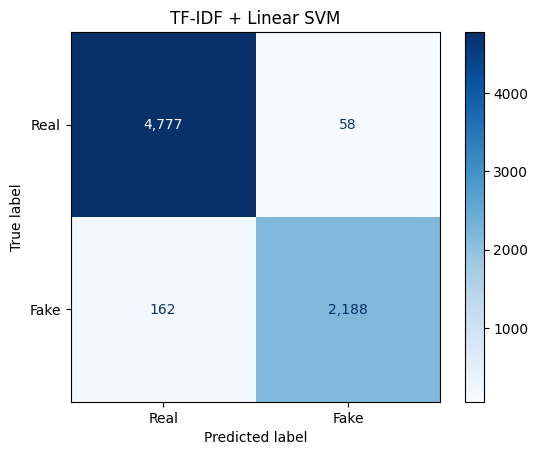

,0
accuracy,0.9694
precision,0.9742
recall,0.9311
f1,0.9521


In [6]:
test_pred = model.predict(X_test)
test_metrics = evaluate_on_test(test_pred, 'TF-IDF + Linear SVM')
pd.Series(test_metrics).round(4)

## Robustness check: how much of the score is real?
Read this table before quoting the headline score. IFND has two known weaknesses:

- **Synthetic rows:** about 60% of the fake rows have the source `AUGMENT`. They were generated from other fake headlines, so a test row can closely resemble a training row.
- **Giveaway words:** fake rows mostly come from fact-checking sites, so their headlines contain words like "fact check" or "viral". Those words identify the publisher's style, not whether a claim is false.

Lower scores in the last rows show how heavily the model relies on these patterns. The word list comes from inspecting the data, so treat this as an indicator rather than a precise measurement.

In [7]:
robustness = robustness_check(test_pred)
robustness

,rows,fake_rows,accuracy,precision,recall,f1
subset,,,,,,
All test headlines,7185,2350,0.9694,0.9742,0.9311,0.9521
Excluding synthetic (AUGMENT),5860,1025,0.9802,0.9434,0.9434,0.9434
Without giveaway words,5193,462,0.9640,0.8852,0.6840,0.7717
Neither synthetic nor giveaway,4922,191,0.9817,0.7760,0.7435,0.7594


## 6. What the model learned
A large positive weight pushes a headline towards Fake, and a large negative weight towards Real.

In [8]:
terms = model.named_steps['tfidf'].get_feature_names_out()
weights = model.named_steps['clf'].coef_[0]
order = np.argsort(weights)
print('Strongest signs of FAKE:', ', '.join(terms[order[-20:]][::-1]))
print('Strongest signs of REAL:', ', '.join(terms[order[:20]]))

Strongest signs of FAKE: did, fake, fact, viral, fact check, shared, video, factcheck, false, check, image, falsely, photo, claim, not, hoax, here, is not, ha not, news
Strongest signs of REAL: sc, covid, year old, tell, to check, fast fact, say, dy, seek, jaishankar, mea, fast, probe, health ministry, complaint, in video, firm, like, not to, the week


## 7. Save results and try a headline
An SVM outputs a distance from the margin rather than a probability; positive means Fake.

In [9]:
save_results(2, 'TF-IDF + Linear SVM', test_pred, test_metrics, robustness,
             {'best_params': search.best_params_, 'cv_f1': search.best_score_})
os.makedirs('models', exist_ok=True)
joblib.dump(model, 'models/tfidf_svm.joblib')

def predict_headline(headline):
    margin = model.decision_function([preprocess(repair_text(headline))])[0]
    return f"{'FAKE' if margin >= 0 else 'REAL'} (margin score: {margin:+.2f})"

print(predict_headline('Supreme Court seeks response from Centre on new highway plea'))
print(predict_headline('Viral video claims the government will give free phones to all students'))

Saved to the results folder
REAL (margin score: -1.54)
FAKE (margin score: +1.30)


In [12]:
import os
import zipfile
from google.colab import files

zip_filename = 'all_project_data.zip'

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # Add the dataset
    if os.path.exists('IFND.csv'):
        zipf.write('IFND.csv')

    # Add the results directory
    if os.path.exists('results'):
        for root, dirs, files_in_dir in os.walk('results'):
            for file in files_in_dir:
                zipf.write(os.path.join(root, file))

    # Add the models directory
    if os.path.exists('models'):
        for root, dirs, files_in_dir in os.walk('models'):
            for file in files_in_dir:
                zipf.write(os.path.join(root, file))

print("Created zip archive with all datasets, models, and evaluation outputs.")
files.download(zip_filename)

Created zip archive with all datasets, models, and evaluation outputs.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Upload to GitHub
1. Create the branch `student-2-tfidf-svm` in the shared repository.
2. In Colab, choose **File > Save a copy in GitHub**, then select the repository and this branch.
3. Add `results/student_2_metrics.json` to the same branch using **Add file > Upload files** on GitHub.

Do not commit `IFND.csv` or saved model files. The dataset's authors allow research use only and ask users to cite: Sharma, D. K., & Garg, S. (2021). *IFND: a benchmark dataset for fake news detection.* Complex & Intelligent Systems.